# SESSION 7 - Data Cleaning (Part 2: Outliers & Data Types)

**Curriculum Module:** Data Collection, Cleaning, Visualization and Analysis  
**Session:** 07 - Data Cleaning (Part 2: Outliers & Data Types)  
**Status:** ✅ Completed

---

## 📋 Topics Covered
1. **Outlier Detection Techniques**:
   - Interquartile Range (IQR) method: $IQR = Q3 - Q1$, Lower Bound $= Q1 - 1.5 \times IQR$, Upper Bound $= Q3 + 1.5 \times IQR$.
   - Visual Outlier Inspection via Matplotlib Boxplots (`plt.boxplot()`).
2. **Outlier Treatment & Transformation**:
   - **Winsorization / Capping & Flooring**: Restricting extreme percentile values to threshold percentiles (e.g. 5th and 95th).
3. **Data Type Conversions & Normalization**:
   - Cleaning string-formatted financial/currency values into numeric types (`str.replace()`, `.astype()`).
   - Resolving mixed data types (boolean/string/integer mixups) into standardized boolean flags.


---

## Task 1: Outlier Detection using the IQR Method

**Problem Statement:**  
*Given a CSV file containing Zomato restaurant ratings, use pandas to detect outliers in the `user_rating` column using the IQR method and print the indices of the detected outliers.*


In [1]:
import pandas as pd
import numpy as np

# Load Zomato restaurant ratings dataset
df_zomato = pd.read_csv('zomato_user_ratings.csv')
print('Zomato Ratings Dataset Preview:')
print(df_zomato.head(5))

# Step 1: Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df_zomato['user_rating'].quantile(0.25)
Q3 = df_zomato['user_rating'].quantile(0.75)
IQR = Q3 - Q1

# Step 2: Compute lower and upper cutoff bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f'\nQ1 (25th Percentile): {Q1:.2f}')
print(f'Q3 (75th Percentile): {Q3:.2f}')
print(f'Interquartile Range (IQR): {IQR:.2f}')
print(f'Lower Bound: {lower_bound:.2f}')
print(f'Upper Bound: {upper_bound:.2f}')

# Step 3: Identify outliers and print their row indices
outlier_mask = (df_zomato['user_rating'] < lower_bound) | (df_zomato['user_rating'] > upper_bound)
outlier_indices = df_zomato.index[outlier_mask].tolist()

print(f'\nIndices of detected outliers: {outlier_indices}')
print('\nOutlier Records:')
df_zomato.loc[outlier_indices]


Zomato Ratings Dataset Preview:
   restaurant_id restaurant_name  user_rating
0              1        Truffles          4.4
1              2        Bawarchi          4.2
2              3       Peter Cat          4.3
3              4        Bademiya          4.1
4              5         Karim's          4.0

Q1 (25th Percentile): 4.00
Q3 (75th Percentile): 4.40
Interquartile Range (IQR): 0.40
Lower Bound: 3.40
Upper Bound: 5.00

Indices of detected outliers: [14, 15, 19]

Outlier Records:
    restaurant_id           restaurant_name  user_rating
14             15       Fake Review Spammer          0.8
15             16        Gourmet Bot Glitch          9.5
19             20  Suspicious Ghost Kitchen          1.2


,restaurant_id,restaurant_name,user_rating
14,15,Fake Review Spammer,0.8
15,16,Gourmet Bot Glitch,9.5
19,20,Suspicious Ghost Kitchen,1.2


---

## Task 2: Visual Outlier Identification with Boxplot

**Problem Statement:**  
*Create a boxplot for the `order_amount` column from a Swiggy orders dataset using matplotlib, and visually identify any outliers present.*  
*Hint: Use `plt.boxplot()` and label your axes for clarity.*


Upper Whisker Threshold: ₹686.25
Visually and numerically identified outliers:
    order_id user_id  order_amount
14      1015    U115        2850.0
18      1019    U119        4100.0


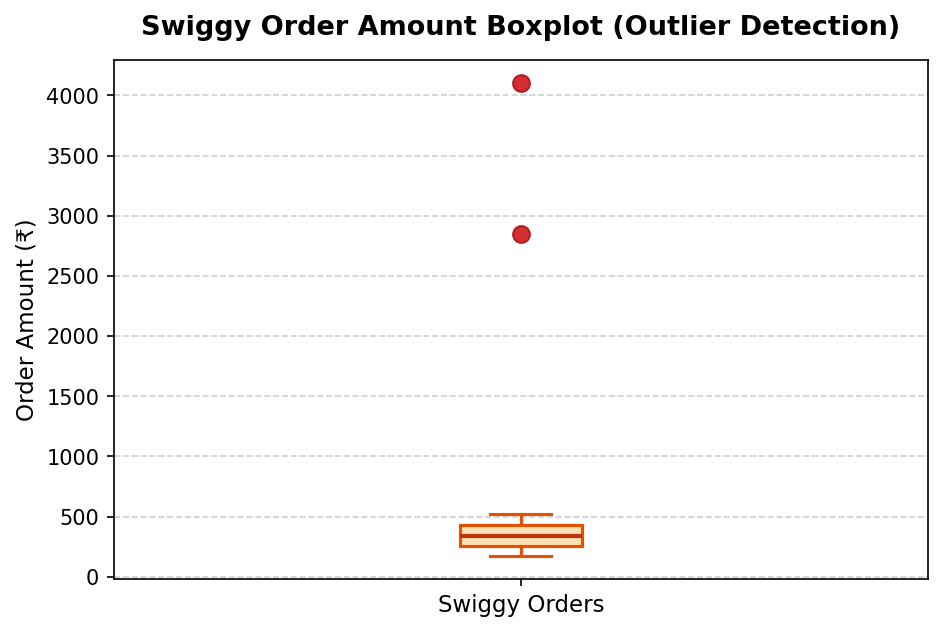

In [2]:
import matplotlib.pyplot as plt

# Load Swiggy orders dataset
df_swiggy = pd.read_csv('swiggy_orders.csv')

# Plot boxplot using matplotlib
plt.figure(figsize=(7, 4.5), dpi=150)
plt.boxplot(
    df_swiggy['order_amount'],
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor='#FFE0B2', color='#E65100', linewidth=1.5),
    medianprops=dict(color='#BF360C', linewidth=2),
    whiskerprops=dict(color='#E65100', linewidth=1.5),
    capprops=dict(color='#E65100', linewidth=1.5),
    flierprops=dict(marker='o', markerfacecolor='#D32F2F', markeredgecolor='#B71C1C', markersize=8)
)

plt.title('Swiggy Order Amount Distribution & Outlier Detection', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Order Amount (₹)', fontsize=11)
plt.xticks([1], ['Swiggy Orders'], fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# Identify and print outliers beyond the upper whisker
q1_swiggy = df_swiggy['order_amount'].quantile(0.25)
q3_swiggy = df_swiggy['order_amount'].quantile(0.75)
iqr_swiggy = q3_swiggy - q1_swiggy
upper_whisker = q3_swiggy + 1.5 * iqr_swiggy
outliers_swiggy = df_swiggy[df_swiggy['order_amount'] > upper_whisker]

print(f'Upper Whisker Threshold: ₹{upper_whisker:.2f}')
print('Visually and numerically identified outliers:')
print(outliers_swiggy[['order_id', 'user_id', 'order_amount']])


---

## Task 3: Winsorization (Percentile Capping & Flooring)

**Problem Statement:**  
*Apply winsorization to the `transaction_amount` column in a Paytm transactions DataFrame to cap all values above the 95th percentile and below the 5th percentile, then display the updated column statistics.*


In [3]:
# Load Paytm transactions dataset
df_paytm = pd.read_csv('paytm_transactions.csv')

print('Original Transaction Amount Statistics:')
print(df_paytm['transaction_amount'].describe().round(2))

# Calculate 5th percentile (floor) and 95th percentile (ceiling)
p05 = df_paytm['transaction_amount'].quantile(0.05)
p95 = df_paytm['transaction_amount'].quantile(0.95)

print(f'\n5th Percentile Floor Cap:    ₹{p05:.2f}')
print(f'95th Percentile Ceiling Cap:  ₹{p95:.2f}')

# Apply Winsorization via pandas clip()
df_paytm['transaction_amount_winsorized'] = df_paytm['transaction_amount'].clip(lower=p05, upper=p95)

print('\nUpdated Transaction Amount Statistics (After Winsorization):')
stats_comparison = pd.DataFrame({
    'Original': df_paytm['transaction_amount'].describe(),
    'Winsorized (5%-95%)': df_paytm['transaction_amount_winsorized'].describe()
}).round(2)
stats_comparison


Original Transaction Amount Statistics:
count       20.00
mean      1946.58
std       5101.18
min          1.50
25%        101.25
50%        305.00
75%        530.00
max      18500.00

5th Percentile Floor Cap:    ₹14.33
95th Percentile Ceiling Cap:  ₹15175.00

Updated Transaction Amount Statistics (After Winsorization):
       Original  Winsorized (5%-95%)
count     20.00                20.00
mean    1946.58              1780.97
std     5101.18              4558.37
min        1.50                14.32
25%      101.25               101.25
50%      305.00               305.00
75%      530.00               530.00
max    18500.00             15175.00


,Original,Winsorized (5%-95%)
count,20.00,20.00
mean,1946.58,1780.97
std,5101.18,4558.37
min,1.50,14.32
25%,101.25,101.25
50%,305.00,305.00
75%,530.00,530.00
max,18500.00,15175.00


---

## Task 4: Cleaning String Currency & Data Type Conversion

**Problem Statement:**  
*You have a DataFrame of Flipkart product prices stored as strings with currency symbols (e.g., `'₹1,299'`). Convert this column to numeric type using pandas, ensuring all non-numeric characters are removed.*  
*Hint: Use `str.replace()` and `astype()`.*


In [4]:
# Load Flipkart products dataset
df_flipkart = pd.read_csv('flipkart_prices.csv')

print('Original Flipkart Products Data:')
print(df_flipkart)
print(f'Original price column dtype: {df_flipkart["price"].dtype}')

# Remove currency symbol '₹' and comma separators ',', then convert to float
df_flipkart['price_cleaned'] = (
    df_flipkart['price']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
    .astype(float)
)

print('\nConverted Flipkart Products Data:')
print(df_flipkart[['product_name', 'price', 'price_cleaned']])
print(f'New price_cleaned column dtype: {df_flipkart["price_cleaned"].dtype}')


Original Flipkart Products Data:
  product_id                   product_name    price  price_numeric
0       P101               boAt Rockerz 450   ₹1,299         1299.0
1       P102                Apple iPhone 15  ₹71,999        71999.0
2       P103         SanDisk 128GB Pendrive     ₹649          649.0
3       P104          Samsung Galaxy Tab S9  ₹42,499        42499.0
4       P105  Fastrack Limitless Smartwatch   ₹1,499         1499.0
5       P106                Sony WH-1000XM5  ₹26,990        26990.0
6       P107              HP Wireless Mouse     ₹499          499.0
7       P108        Dell Inspiron 15 Laptop  ₹54,990        54990.0
Original price column dtype: object

Converted Flipkart Products Data:
                    product_name    price  price_numeric
0               boAt Rockerz 450   ₹1,299         1299.0
1                Apple iPhone 15  ₹71,999        71999.0
2         SanDisk 128GB Pendrive     ₹649          649.0
3          Samsung Galaxy Tab S9  ₹42,499        42499.0

,product_name,price,price_numeric
0,boAt Rockerz 450,"₹1,299",1299.0
1,Apple iPhone 15,"₹71,999",71999.0
2,SanDisk 128GB Pendrive,₹649,649.0
3,Samsung Galaxy Tab S9,"₹42,499",42499.0
4,Fastrack Limitless Smartwatch,"₹1,499",1499.0
5,Sony WH-1000XM5,"₹26,990",26990.0
6,HP Wireless Mouse,₹499,499.0
7,Dell Inspiron 15 Laptop,"₹54,990",54990.0


---

## Task 5: Resolving Mixed-Type Boolean Flags

**Problem Statement:**  
*Fix the following code snippet where the `is_premium` column in a Spotify user DataFrame is a mix of boolean, string, and integer types. Convert the entire column to boolean type, treating `'True'`, `1`, and `'yes'` as `True`, and everything else as `False`.*


In [5]:
# Load Spotify user dataset with mixed boolean values
df_spotify = pd.read_csv('spotify_users.csv')

print('Original Mixed is_premium Values:')
print(df_spotify[['username', 'is_premium']])

# Define the set of truthy representations (case-insensitive string matching)
truthy_values = {'true', '1', 'yes'}

# Normalize to lower-case string, strip whitespaces, and map to boolean
df_spotify['is_premium_clean'] = (
    df_spotify['is_premium']
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(truthy_values)
)

print('\nCleaned and Standardized is_premium Column:')
comparison_table = df_spotify[['user_id', 'username', 'is_premium', 'is_premium_clean']]
print(comparison_table)
print(f'Final is_premium_clean dtype: {df_spotify["is_premium_clean"].dtype}')


Original Mixed is_premium Values:
    username is_premium
0   kathan_g       True
1     arav_m          1
2    priya_s        yes
3    rohit_k      False
4   ananya_d          0
5   vikram_r         no
6    sneha_p        YES
7     neha_t          0
8    tanya_v          1
9   manish_b    unknown
10  deepak_n        NaN
11  ishita_c       true

Cleaned and Standardized is_premium Column:
    user_id  username is_premium  is_premium_clean
0       101  kathan_g       True              True
1       102    arav_m          1              True
2       103   priya_s        yes              True
3       104   rohit_k      False             False
4       105  ananya_d          0             False
5       106  vikram_r         no             False
6       107   sneha_p        YES              True
7       108    neha_t          0             False
8       109   tanya_v          1              True
9       110  manish_b    unknown             False
10      111  deepak_n        NaN             Fal

,user_id,username,is_premium,is_premium_clean
0,101,kathan_g,True,True
1,102,arav_m,1,True
2,103,priya_s,yes,True
3,104,rohit_k,False,False
4,105,ananya_d,0,False
5,106,vikram_r,no,False
6,107,sneha_p,YES,True
7,108,neha_t,0,False
8,109,tanya_v,1,True
9,110,manish_b,unknown,False


---

## 🎯 Key Takeaways & Best Practices
- **IQR for Outlier Detection**: The IQR rule is robust to extreme skewness compared to Z-scores because quartiles are non-parametric and resistant to extreme values.
- **Boxplot Diagnostics**: The whiskers span $1.5 \times IQR$; any point outside is flagged as an outlier (fliers), giving instant visual cues on distribution shape.
- **Winsorization vs. Trimming**: Deleting outliers discards valid observations. Winsorization limits extreme influence while retaining sample size and degrees of freedom.
- **String Cleaning & Type Casting**: Raw tabular data frequently stores numbers with currency signs (`₹`, `$`) and commas (`,`). Always strip non-numeric characters before invoking `.astype(float)` to prevent `ValueError`.
- **Boolean Standardization**: Avoid raw `.astype(bool)` on string objects because Python treats *any* non-empty string (including `'False'` and `'0'`) as `True`! Use explicit membership checks (`.isin({'true', '1', 'yes'})`) instead.
